# Contexto do Problema e Dicionario de Dados

Instituicoes financeiras precisam estimar o risco de credito antes de aprovar uma solicitacao. Este projeto usa `data/dataset.csv` para classificar cada solicitante como **Baixo**, **Medio** ou **Alto** risco. A predicao apoia a triagem e a analise humana, mas nao substitui a decisao final.

| Nome da coluna | Tipo | Significado pratico |
|---|---|---|
| idade | int | Idade do solicitante em anos |
| renda_mensal | float | Renda mensal em reais |
| tempo_emprego_meses | int | Tempo de emprego em meses |
| score_credito | int | Pontuacao historica de credito |
| possui_imovel | str | Indicador de propriedade de imovel |
| possui_veiculo | str | Indicador de propriedade de veiculo |
| estado_civil | str | Estado civil declarado |
| nivel_escolaridade | str | Maior nivel educacional alcancado |
| indice_divida | float | Percentual aproximado da renda comprometida |
| categoria_risco | str | Variavel alvo: Baixo, Medio ou Alto |

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

raiz = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
df = pd.read_csv(raiz / "data" / "dataset.csv")
df.head()

,idade,renda_mensal,tempo_emprego_meses,score_credito,possui_imovel,possui_veiculo,estado_civil,nivel_escolaridade,indice_divida,categoria_risco
0,69,4388.74,101,546,Sim,Sim,Divorciado,Pos-graduacao,95.30,Alto
1,57,4176.91,284,812,Sim,Nao,Solteiro,Pos-graduacao,17.27,Medio
2,70,3515.48,427,697,Sim,Nao,Divorciado,Fundamental,8.72,Medio
3,67,4497.03,240,509,Sim,Sim,Solteiro,Fundamental,84.54,Alto
4,62,8753.48,224,378,Sim,Sim,Divorciado,Fundamental,9.49,Medio


# Analise Exploratória Resumida

In [4]:
print("Formato:", df.shape)
print("\nValores ausentes/nulos:")
print(df.isna().sum())
print("\nContagem da variavel alvo:")
print(df["categoria_risco"].value_counts())

Formato: (800, 10)

Valores ausentes/nulos:
idade                  0
renda_mensal           0
tempo_emprego_meses    0
score_credito          0
possui_imovel          0
possui_veiculo         0
estado_civil           0
nivel_escolaridade     0
indice_divida          0
categoria_risco        0
dtype: int64

Contagem da variavel alvo:
categoria_risco
Medio    518
Alto     225
Baixo     57
Name: count, dtype: int64


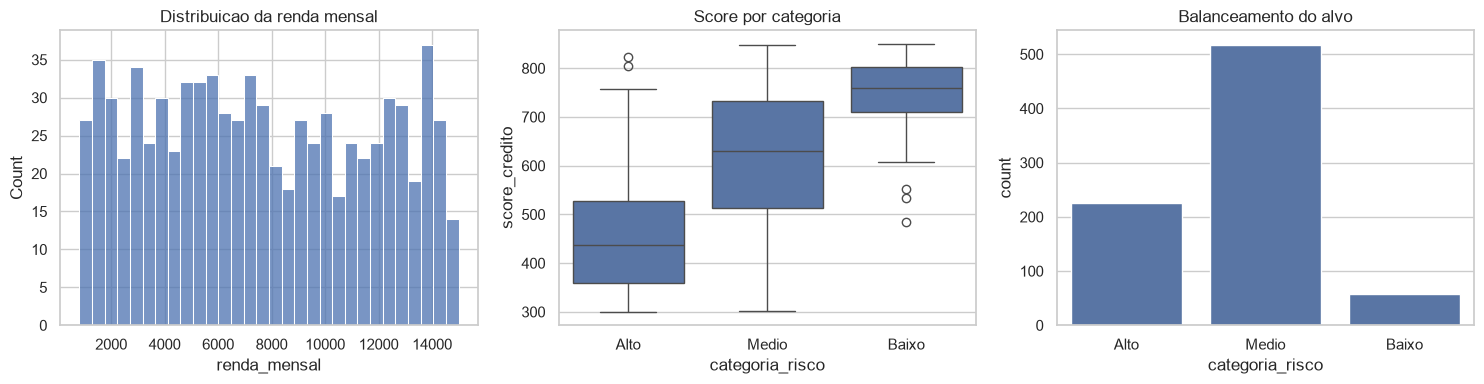

In [5]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df["renda_mensal"], bins=30, ax=axes[0])
axes[0].set_title("Distribuicao da renda mensal")
sns.boxplot(data=df, x="categoria_risco", y="score_credito", ax=axes[1])
axes[1].set_title("Score por categoria")
sns.countplot(data=df, x="categoria_risco", ax=axes[2])
axes[2].set_title("Balanceamento do alvo")
plt.tight_layout()
plt.show()

# Construcao do Pipeline Scikit-Learn

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier

X = df.drop(columns="categoria_risco")
y = df["categoria_risco"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=77, stratify=y
)

colunas_numericas = X.select_dtypes(include=np.number).columns.tolist()
colunas_categoricas = X.select_dtypes(exclude=np.number).columns.tolist()

preprocessador = ColumnTransformer(
    transformers=[
        ("numericas", StandardScaler(), colunas_numericas),
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"),
            colunas_categoricas,
        ),
    ]
)

mlp = MLPClassifier(
    hidden_layer_sizes=(128, 64, 32),
    learning_rate_init=0.001,
    max_iter=500,
    random_state=77,
    early_stopping=True,
)

pipeline = Pipeline([
    ("preprocessamento", preprocessador),
    ("mlp", mlp),
])

pipeline.fit(X_treino, y_treino)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessamento', ...), ('mlp', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[<U5](3,)","['Alto','Baixo','Medio']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['idade','renda_mensal','tempo_emprego_meses',...,'estado_civil', 'nivel_escolaridade','indice_divida']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default

# Avaliacao do Modelo

In [8]:
from sklearn.metrics import accuracy_score, matthews_corrcoef, confusion_matrix, ConfusionMatrixDisplay

y_pred = pipeline.predict(X_teste)
print(f"Acuracia global: {accuracy_score(y_teste, y_pred):.4f}")
print(f"Matthews correlation coefficient: {matthews_corrcoef(y_teste, y_pred):.4f}")

Acuracia global: 0.9313
Matthews correlation coefficient: 0.8583


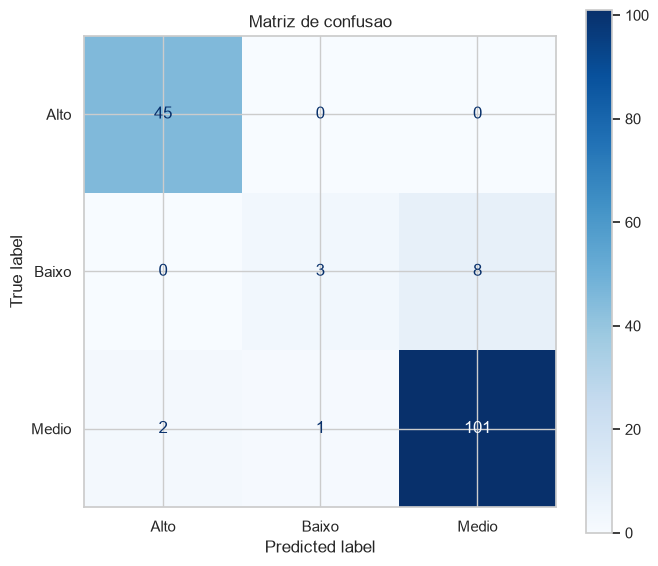

In [9]:
rotulos = sorted(y.unique())
matriz = confusion_matrix(y_teste, y_pred, labels=rotulos)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(matriz, display_labels=rotulos).plot(ax=ax, cmap="Blues")
ax.set_title("Matriz de confusao")
plt.tight_layout()
plt.show()

# Exportacao do Modelo Treinado

In [10]:
import joblib

(raiz / "models").mkdir(parents=True, exist_ok=True)
joblib.dump(pipeline, raiz / "models" / "modelo_mlp.joblib")
print("Modelo exportado para models/modelo_mlp.joblib")

Modelo exportado para models/modelo_mlp.joblib
